# EDA de P2: riesgo operativo por estación y hora

Este notebook explora solamente lo necesario para diseñar P2. La meta es entender las entradas, salidas y el flujo neto por estación-hora antes de definir las clases de riesgo.

- **Entrenamiento:** 2024.
- **Validación:** 2025.
- **Prueba:** enero-septiembre de 2026, que no se consulta en este EDA.
- **Horizonte:** las siguientes 2 horas.


## Datos utilizados y decisiones de privacidad

Para P2 solo necesitamos las fechas de inicio y fin, las estaciones de origen y destino, y la capacidad de cada estación. No utilizamos `usuario_id`, género ni año de nacimiento porque no aportan a este análisis operativo y evitamos tratar datos personales innecesarios.

La nomenclatura disponible corresponde a septiembre de 2026. En este proyecto la capacidad se trata como un atributo estático. Esto es una limitación, porque la capacidad de una estación pudo cambiar durante 2024 o 2025.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from mibici_mlops.config import (
    P2_FIN_ENTRENAMIENTO,
    P2_FIN_VALIDACION,
    P2_HORIZONTE_HORAS,
    P2_INICIO_ENTRENAMIENTO,
    P2_INICIO_VALIDACION,
    PROCESSED_DATA_DIR,
    SEMILLA_ALEATORIA,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda valor: f"{valor:,.4f}")


2026-10-17 15:26:44.271 | INFO     | mibici_mlops.config:<module>:11 - PROJ_ROOT path is: C:\Users\ingri\Documents\Maestria\MLOps\TC5061-Proyecto-Equipo51


## 1. Localizar los archivos

Se cargan únicamente los 24 meses de 2024 y 2025. Los nueve archivos de 2026 quedan reservados para la evaluación final.


In [2]:
directorio_viajes = PROCESSED_DATA_DIR / "trips"
directorio_nomenclatura = PROCESSED_DATA_DIR / "nomenclature"

rutas_viajes = sorted(
    ruta
    for ruta in directorio_viajes.glob("*.parquet")
    if ruta.name.startswith(("datos_abiertos_2024_", "datos_abiertos_2025_"))
)
rutas_nomenclatura = sorted(directorio_nomenclatura.glob("*.parquet"))

assert len(rutas_viajes) == 24, f"Se esperaban 24 archivos y se encontraron {len(rutas_viajes)}."
assert len(rutas_nomenclatura) == 1, "Se esperaba un archivo de nomenclatura."

print("Archivos mensuales:", len(rutas_viajes))
print("Primer archivo:", rutas_viajes[0].name)
print("Último archivo:", rutas_viajes[-1].name)
print("Nomenclatura:", rutas_nomenclatura[0].name)


Archivos mensuales: 24
Primer archivo: datos_abiertos_2024_01.parquet
Último archivo: datos_abiertos_2025_12.parquet
Nomenclatura: nomenclatura_2026_09.parquet


## 2. Revisar el esquema real

Nombres y tipos que recibe P2 después de la ingesta.


In [3]:
columnas_operativas = [
    "inicio_del_viaje",
    "fin_del_viaje",
    "origen_id",
    "destino_id",
]
muestra_viajes = pd.read_parquet(
    rutas_viajes[0],
    columns=columnas_operativas,
).head(3)
nomenclatura = pd.read_parquet(rutas_nomenclatura[0])

print("Columnas de viajes:")
display(muestra_viajes.dtypes.rename("tipo").to_frame())
display(muestra_viajes)

print("Columnas de nomenclatura:")
display(nomenclatura.dtypes.rename("tipo").to_frame())
display(nomenclatura.head(3))


Columnas de viajes:


,tipo
inicio_del_viaje,datetime64[ns]
fin_del_viaje,datetime64[ns]
origen_id,int64
destino_id,int64


,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254


Columnas de nomenclatura:


,tipo
station_id,int64
station_name,object
latitude,float64
longitude,float64
capacity,int64


,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.6664,-103.3488,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.6672,-103.3660,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.6677,-103.3683,19


## 3. Convertir viajes a movimientos estación-hora

Cada inicio de viaje cuenta como una salida de la estación de origen. Cada fin de viaje cuenta como una entrada a la estación de destino.

Se procesa un mes a la vez para no cargar los 24 archivos completos al mismo tiempo.


In [4]:
def agrupar_viajes_por_estacion_hora(ruta: Path) -> pd.DataFrame:
    """Cuenta entradas y salidas por estación-hora para un archivo mensual."""
    viajes = pd.read_parquet(
        ruta,
        columns=[
            "inicio_del_viaje",
            "fin_del_viaje",
            "origen_id",
            "destino_id",
        ],
    )

    salidas = (
        viajes.assign(
            estacion_id=viajes["origen_id"],
            fecha_hora=viajes["inicio_del_viaje"].dt.floor("h"),
        )[["estacion_id", "fecha_hora"]]
        .groupby(["estacion_id", "fecha_hora"])
        .size()
        .rename("salidas")
        .reset_index()
    )

    entradas = (
        viajes.assign(
            estacion_id=viajes["destino_id"],
            fecha_hora=viajes["fin_del_viaje"].dt.floor("h"),
        )[["estacion_id", "fecha_hora"]]
        .groupby(["estacion_id", "fecha_hora"])
        .size()
        .rename("entradas")
        .reset_index()
    )

    return salidas.merge(
        entradas,
        how="outer",
        on=["estacion_id", "fecha_hora"],
    )


In [5]:
movimientos_mensuales = []

for numero, ruta in enumerate(rutas_viajes, start=1):
    movimientos_mensuales.append(agrupar_viajes_por_estacion_hora(ruta))
    print(f"Procesado {numero:02d}/24: {ruta.name}", end="\r")

flujos_con_actividad = (
    pd.concat(movimientos_mensuales, ignore_index=True)
    .groupby(["estacion_id", "fecha_hora"], as_index=False)[["salidas", "entradas"]]
    .sum()
)
flujos_con_actividad[["salidas", "entradas"]] = (
    flujos_con_actividad[["salidas", "entradas"]].fillna(0).astype("int32")
)
flujos_con_actividad = flujos_con_actividad[
    (flujos_con_actividad["fecha_hora"] >= P2_INICIO_ENTRENAMIENTO)
    & (flujos_con_actividad["fecha_hora"] < P2_FIN_VALIDACION)
].copy()

print("\nFilas estación-hora con al menos un movimiento:", f"{len(flujos_con_actividad):,}")
print("Estaciones observadas:", flujos_con_actividad["estacion_id"].nunique())


Procesado 24/24: datos_abiertos_2025_12.parquet
Filas estación-hora con al menos un movimiento: 3,762,187
Estaciones observadas: 373


## 4. Crear una fila por cada estación y cada hora

Los archivos originales solo tienen registros cuando ocurre un viaje, pero P2 necesita una línea de tiempo continua. Por eso, entre la primera y la última aparición de cada estación, agregamos las horas faltantes con cero entradas y cero salidas.

Estas filas indican que no se registró movimiento durante esa hora. También permiten que la siguiente fila represente realmente la siguiente hora.


In [6]:
def crear_rejilla_de_horas_activas(flujos: pd.DataFrame) -> pd.DataFrame:
    """Crea una fila por hora dentro del periodo observado de cada estación."""
    intervalos = (
        flujos.groupby("estacion_id")["fecha_hora"]
        .agg(inicio="min", fin="max")
        .reset_index()
    )

    partes = [
        pd.DataFrame(
            {
                "estacion_id": fila.estacion_id,
                "fecha_hora": pd.date_range(fila.inicio, fila.fin, freq="h"),
            }
        )
        for fila in intervalos.itertuples(index=False)
    ]
    return pd.concat(partes, ignore_index=True)


rejilla = crear_rejilla_de_horas_activas(flujos_con_actividad)
estacion_hora = rejilla.merge(
    flujos_con_actividad,
    how="left",
    on=["estacion_id", "fecha_hora"],
)
estacion_hora[["salidas", "entradas"]] = (
    estacion_hora[["salidas", "entradas"]].fillna(0).astype("int32")
)

nomenclatura_p2 = nomenclatura[
    ["station_id", "station_name", "latitude", "longitude", "capacity"]
].rename(
    columns={
        "station_id": "estacion_id",
        "station_name": "nombre_estacion",
        "latitude": "latitud",
        "longitude": "longitud",
        "capacity": "capacidad",
    }
)
estacion_hora = estacion_hora.merge(nomenclatura_p2, how="left", on="estacion_id")

print("Filas estación-hora agregando horas sin viajes:", f"{len(estacion_hora):,}")


Filas estación-hora agregando horas sin viajes: 6,376,929


## 5. Verificar que cada estación activa tenga una capacidad válida

Ahora unimos las estaciones observadas en los viajes con la nomenclatura. Necesitamos la capacidad porque más adelante dividiremos el flujo entre el número de espacios de cada estación.

Antes de continuar, reportamos si alguna estación activa no aparece en la nomenclatura o tiene capacidad igual a cero. En esos casos no sería posible calcular el flujo normalizado de forma correcta.


In [7]:
estaciones_sin_nomenclatura = sorted(
    estacion_hora.loc[estacion_hora["capacidad"].isna(), "estacion_id"].unique().tolist()
)
estaciones_capacidad_no_positiva = sorted(
    estacion_hora.loc[estacion_hora["capacidad"].fillna(0).le(0), "estacion_id"]
    .unique()
    .tolist()
)

resumen_calidad = pd.Series(
    {
        "archivos_mensuales": len(rutas_viajes),
        "filas_con_actividad": len(flujos_con_actividad),
        "filas_estacion_hora": len(estacion_hora),
        "estaciones_observadas": estacion_hora["estacion_id"].nunique(),
        "estaciones_sin_nomenclatura": len(estaciones_sin_nomenclatura),
        "estaciones_con_capacidad_no_positiva": len(estaciones_capacidad_no_positiva),
    },
    name="valor",
)

display(resumen_calidad.to_frame())
print("IDs sin nomenclatura:", estaciones_sin_nomenclatura)
print("IDs con capacidad no positiva:", estaciones_capacidad_no_positiva)


,valor
archivos_mensuales,24
filas_con_actividad,3762187
filas_estacion_hora,6376929
estaciones_observadas,373
estaciones_sin_nomenclatura,0
estaciones_con_capacidad_no_positiva,0


IDs sin nomenclatura: []
IDs con capacidad no positiva: []


## 6. Convertir los movimientos en una medida de riesgo futuro

Primero calculamos el `flujo_neto = entradas - salidas`. Un valor negativo indica que salieron más bicicletas de las que llegaron; uno positivo indica lo contrario.

Después dividimos el flujo entre la capacidad para poder comparar estaciones de distintos tamaños. Finalmente, sumamos el flujo de las siguientes dos horas y lo normalizamos por capacidad. A este resultado lo llamamos `presion_futura_2h`.

Esta presión es una aproximación del riesgo. No representa el inventario real de bicicletas porque MiBici no publica ese dato histórico.


In [8]:
estacion_hora = estacion_hora[estacion_hora["capacidad"].gt(0)].copy()
estacion_hora = estacion_hora.sort_values(["estacion_id", "fecha_hora"]).reset_index(drop=True)
estacion_hora["capacidad"] = estacion_hora["capacidad"].astype("int16")
estacion_hora["flujo_neto"] = estacion_hora["entradas"] - estacion_hora["salidas"]
estacion_hora["flujo_normalizado"] = (
    estacion_hora["flujo_neto"] / estacion_hora["capacidad"]
)

flujo_por_estacion = estacion_hora.groupby("estacion_id", sort=False)["flujo_neto"]
estacion_hora["presion_futura_2h"] = (
    flujo_por_estacion.shift(-1) + flujo_por_estacion.shift(-2)
) / estacion_hora["capacidad"]

display(
    estacion_hora[
        ["estacion_id", "fecha_hora", "entradas", "salidas", "flujo_neto", "capacidad", "presion_futura_2h"]
    ].head()
)


,estacion_id,fecha_hora,entradas,salidas,flujo_neto,capacidad,presion_futura_2h
0,2,2024-01-01 07:00:00,1,0,1,15,-0.0667
1,2,2024-01-01 08:00:00,0,1,-1,15,-0.1333
2,2,2024-01-01 09:00:00,1,1,0,15,-0.1333
3,2,2024-01-01 10:00:00,0,2,-2,15,-0.1333
4,2,2024-01-01 11:00:00,0,0,0,15,-0.2000


### Ejemplo de lectura: estación 2 a las 07:00

En la fila de las **07:00**, la estación recibió una bicicleta y no registró salidas:

`flujo_neto = entradas - salidas = 1 - 0 = 1`

Sin embargo, `presion_futura_2h` representa lo que ocurre en las **dos horas siguientes**, no durante las 07:00:

- A las 08:00, el flujo neto es `-1`.
- A las 09:00, el flujo neto es `0`.

Por lo tanto:

`presion_futura_2h = (-1 + 0) / 15 = -0.0667`

El flujo actual puede ser positivo y la presión futura negativa, porque representan momentos diferentes.

## 7. Separar 2024 y 2025 sin mezclar información futura

Usamos 2024 como entrenamiento y 2025 como validación. La separación se hace por fecha, sin revolver las filas, para que el modelo siempre sea evaluado con datos posteriores a los que utilizó para aprender.

También excluimos las últimas dos horas de cada periodo, porque su resultado necesitaría consultar horas del siguiente conjunto. Los datos de 2026 continúan reservados para la prueba final.


In [9]:
inicio_entrenamiento = pd.Timestamp(P2_INICIO_ENTRENAMIENTO)
fin_entrenamiento_seguro = pd.Timestamp(P2_FIN_ENTRENAMIENTO) - pd.Timedelta(
    hours=P2_HORIZONTE_HORAS
)
inicio_validacion = pd.Timestamp(P2_INICIO_VALIDACION)
fin_validacion_seguro = pd.Timestamp(P2_FIN_VALIDACION) - pd.Timedelta(
    hours=P2_HORIZONTE_HORAS
)

estacion_hora["conjunto"] = pd.Series(pd.NA, index=estacion_hora.index, dtype="string")
mascara_entrenamiento = estacion_hora["fecha_hora"].between(
    inicio_entrenamiento,
    fin_entrenamiento_seguro,
    inclusive="left",
)
mascara_validacion = estacion_hora["fecha_hora"].between(
    inicio_validacion,
    fin_validacion_seguro,
    inclusive="left",
)
estacion_hora.loc[mascara_entrenamiento, "conjunto"] = "entrenamiento"
estacion_hora.loc[mascara_validacion, "conjunto"] = "validacion"

datos_eda = estacion_hora.dropna(subset=["presion_futura_2h", "conjunto"]).copy()

resumen_conjuntos = (
    datos_eda.groupby("conjunto", observed=True)
    .agg(
        filas=("fecha_hora", "size"),
        estaciones=("estacion_id", "nunique"),
        primera_hora=("fecha_hora", "min"),
        ultima_hora=("fecha_hora", "max"),
    )
)
display(resumen_conjuntos)


,filas,estaciones,primera_hora,ultima_hora
conjunto,,,,
entrenamiento,3160639,370,2024-01-01,2024-12-31 21:00:00
validacion,3214808,371,2025-01-01,2025-12-31 21:00:00


## 8. Probar opciones para formar las tres clases de riesgo

Hasta ahora `presion_futura_2h` es un número. Para convertirla en un problema de clasificación necesitamos separar los casos en `riesgo_vaciado`, `normal` y `riesgo_saturacion`.

Comparamos tres pares de cuantiles: 5%/95%, 10%/90% y 15%/85%. Los valores de los umbrales se obtienen solamente con 2024 y después se aplican sin cambios a 2025. La tabla permite revisar cuántos registros quedarían en cada clase antes de elegir una opción.


In [10]:
def clasificar_presion(
    presion: pd.Series,
    umbral_vaciado: float,
    umbral_saturacion: float,
) -> pd.Series:
    """Clasifica la presión futura con dos umbrales ya definidos."""
    clase = pd.Series("normal", index=presion.index, dtype="string")
    clase.loc[presion <= umbral_vaciado] = "riesgo_vaciado"
    clase.loc[presion >= umbral_saturacion] = "riesgo_saturacion"
    return clase


datos_entrenamiento = datos_eda[datos_eda["conjunto"] == "entrenamiento"]
datos_validacion = datos_eda[datos_eda["conjunto"] == "validacion"]
cuantiles = [(0.05, 0.95), (0.10, 0.90), (0.15, 0.85)]
comparaciones = []

for cuantil_bajo, cuantil_alto in cuantiles:
    umbral_vaciado = datos_entrenamiento["presion_futura_2h"].quantile(cuantil_bajo)
    umbral_saturacion = datos_entrenamiento["presion_futura_2h"].quantile(cuantil_alto)

    fila = {
        "cuantiles": f"{cuantil_bajo:.0%}/{cuantil_alto:.0%}",
        "umbral_vaciado": umbral_vaciado,
        "umbral_saturacion": umbral_saturacion,
    }

    for nombre, datos in [("train", datos_entrenamiento), ("validation", datos_validacion)]:
        clases = clasificar_presion(
            datos["presion_futura_2h"],
            umbral_vaciado,
            umbral_saturacion,
        )
        proporciones = clases.value_counts(normalize=True)
        for clase in ["riesgo_vaciado", "normal", "riesgo_saturacion"]:
            fila[f"{nombre}_{clase}"] = proporciones.get(clase, 0)

    comparaciones.append(fila)

comparacion_umbrales = pd.DataFrame(comparaciones)
columnas_porcentaje = [
    columna
    for columna in comparacion_umbrales.columns
    if columna.startswith(("train_", "validation_"))
]
display(
    comparacion_umbrales.style.format(
        {
            "umbral_vaciado": "{:.4f}",
            "umbral_saturacion": "{:.4f}",
            **{columna: "{:.2%}" for columna in columnas_porcentaje},
        }
    )
)


,cuantiles,umbral_vaciado,umbral_saturacion,train_riesgo_vaciado,train_normal,train_riesgo_saturacion,validation_riesgo_vaciado,validation_normal,validation_riesgo_saturacion
0,5%/95%,-0.2667,0.2632,5.45%,89.18%,5.37%,4.97%,90.02%,5.01%
1,10%/90%,-0.1613,0.1579,10.00%,79.50%,10.50%,9.44%,80.59%,9.97%
2,15%/85%,-0.1053,0.1053,16.59%,67.52%,15.89%,16.11%,68.57%,15.31%


La opción **10%/90%** parece un punto medio razonable. Permite identificar suficientes casos de posible vaciado o saturación sin clasificar demasiadas horas como riesgo.

Esto ayuda a mantener un equilibrio entre no dejar pasar posibles faltas de bicicletas o anclajes y no generar demasiadas alertas innecesarias.

Además, las proporciones de las clases son muy parecidas entre entrenamiento (2024) y validación (2025). Esta estabilidad es una buena señal, porque indica que los umbrales mantienen un comportamiento similar en ambos periodos.

Por estas razones, se utilizarán inicialmente los umbrales:

- Riesgo de vaciado: presión menor o igual a `-0.1613`.
- Operación normal: presión entre `-0.1613` y `0.1579`.
- Riesgo de saturación: presión mayor o igual a `0.1579`.

## 9. Revisar visualmente el comportamiento de los datos

Las cuatro gráficas resumen lo necesario para tomar la decisión: el tamaño de las estaciones, las horas con mayor movimiento, la distribución de la presión futura y el balance de clases en 2024 y 2025.

Para que la gráfica de presión sea más rápida se dibuja una muestra reproducible. Los umbrales y las proporciones de clases sí se calcularon con todos los datos disponibles de entrenamiento y validación.


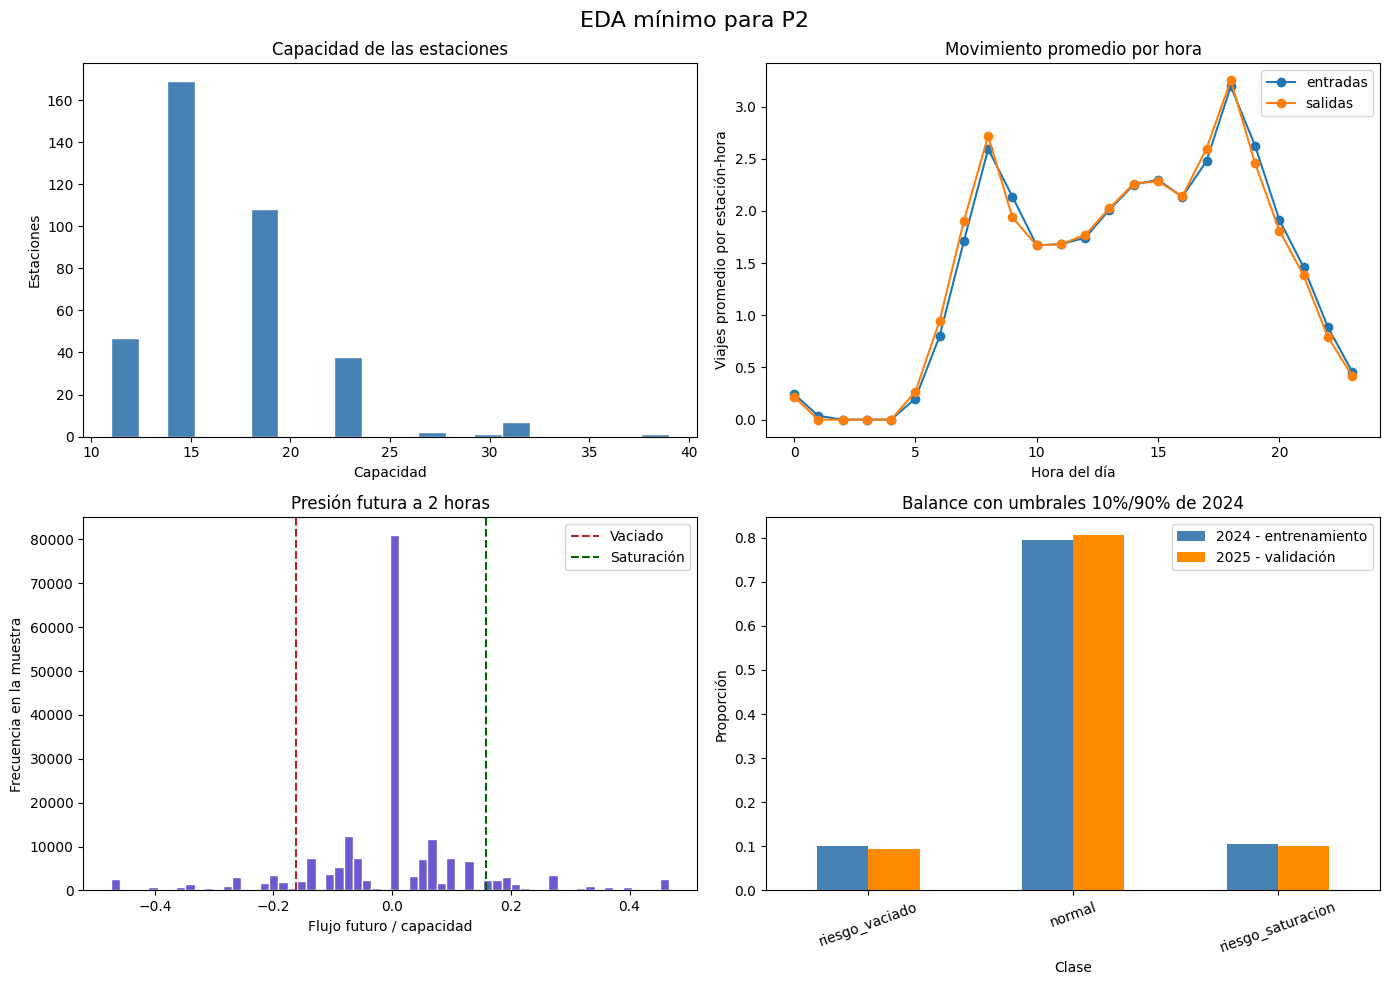

In [11]:
fila_10_90 = comparacion_umbrales.loc[comparacion_umbrales["cuantiles"] == "10%/90%"].iloc[0]
umbral_vaciado_10 = fila_10_90["umbral_vaciado"]
umbral_saturacion_90 = fila_10_90["umbral_saturacion"]

muestra_grafica = datos_eda.sample(
    n=min(200_000, len(datos_eda)),
    random_state=SEMILLA_ALEATORIA,
)
limite_inferior = muestra_grafica["presion_futura_2h"].quantile(0.01)
limite_superior = muestra_grafica["presion_futura_2h"].quantile(0.99)
presion_para_grafica = muestra_grafica["presion_futura_2h"].clip(
    limite_inferior,
    limite_superior,
)

actividad_por_hora = (
    datos_eda.assign(hora=datos_eda["fecha_hora"].dt.hour)
    .groupby("hora")[["entradas", "salidas"]]
    .mean()
)
capacidades = estacion_hora.drop_duplicates("estacion_id")["capacidad"]

clases_entrenamiento = clasificar_presion(
    datos_entrenamiento["presion_futura_2h"],
    umbral_vaciado_10,
    umbral_saturacion_90,
).value_counts(normalize=True)
clases_validacion = clasificar_presion(
    datos_validacion["presion_futura_2h"],
    umbral_vaciado_10,
    umbral_saturacion_90,
).value_counts(normalize=True)
balance_clases = pd.DataFrame(
    {"2024 - entrenamiento": clases_entrenamiento, "2025 - validación": clases_validacion}
).reindex(["riesgo_vaciado", "normal", "riesgo_saturacion"])

figura, ejes = plt.subplots(2, 2, figsize=(14, 10))

ejes[0, 0].hist(capacidades, bins=20, color="steelblue", edgecolor="white")
ejes[0, 0].set_title("Capacidad de las estaciones")
ejes[0, 0].set_xlabel("Capacidad")
ejes[0, 0].set_ylabel("Estaciones")

actividad_por_hora.plot(ax=ejes[0, 1], marker="o")
ejes[0, 1].set_title("Movimiento promedio por hora")
ejes[0, 1].set_xlabel("Hora del día")
ejes[0, 1].set_ylabel("Viajes promedio por estación-hora")

ejes[1, 0].hist(presion_para_grafica, bins=60, color="slateblue", edgecolor="white")
ejes[1, 0].axvline(umbral_vaciado_10, color="firebrick", linestyle="--", label="Vaciado")
ejes[1, 0].axvline(umbral_saturacion_90, color="darkgreen", linestyle="--", label="Saturación")
ejes[1, 0].set_title("Presión futura a 2 horas")
ejes[1, 0].set_xlabel("Flujo futuro / capacidad")
ejes[1, 0].set_ylabel("Frecuencia en la muestra")
ejes[1, 0].legend()

balance_clases.plot(kind="bar", ax=ejes[1, 1], color=["steelblue", "darkorange"])
ejes[1, 1].set_title("Balance con umbrales 10%/90% de 2024")
ejes[1, 1].set_xlabel("Clase")
ejes[1, 1].set_ylabel("Proporción")
ejes[1, 1].tick_params(axis="x", rotation=20)

figura.suptitle("EDA mínimo para P2", fontsize=16)
figura.tight_layout()
plt.show()


## 10. Conclusiones del EDA

Las gráficas muestran cuatro ideas importantes para construir P2:

- **Capacidad:** las estaciones no tienen el mismo número de anclajes. Por eso usamos `flujo futuro / capacidad` y no solamente el número de viajes.
- **Hora del día:** el movimiento es bajo durante la madrugada y aumenta cerca de las 8:00 y las 18:00. La hora será una característica útil para el modelo.
- **Presión futura:** la mayoría de las horas se concentra cerca de cero, mientras que los valores más negativos y positivos representan los casos de posible vaciado o saturación.
- **Balance de clases:** con la opción 10%/90%, entrenamiento y validación conservan proporciones muy parecidas: aproximadamente 10% de riesgo de vaciado, 80% normal y 10% de riesgo de saturación. Esta estabilidad es una buena señal.

### Decisión para continuar

Se elige inicialmente la opción **10%/90%** porque permite detectar suficientes casos de riesgo sin generar demasiadas alertas. Los umbrales se calcularon únicamente con 2024 y son:

- Riesgo de vaciado: presión menor o igual a **-0.1613**.
- Operación normal: presión entre **-0.1613** y **0.1579**.
- Riesgo de saturación: presión mayor o igual a **0.1579**.

El año 2025 solo se usó para comprobar que la decisión se comporta de forma estable. Los registros de viajes de 2026 no se consultaron en este análisis y se reservan para la evaluación final. Solamente se utilizó la nomenclatura de septiembre de 2026 como referencia estática de las estaciones.
